# 06 Fitting - rev01 - the reaction energies from the equilibrium tubes

|                     |     |
| ------------------- | --- |
| **Status**          | Draft, 2026-10-28. The problem only: nothing is fitted yet |
| **Source**          | Y. Alcaraz Galván; outputs computed from the Tank dataset snapshot (2026-10-08) and NMR data from experiments; the figure of §4 after `tank_model.ipynb` (P. Broqvist, BatteryAsTank) |
| **Scope**           | Why the reaction energies must be fitted before the barriers, what is known of them (computed value and its error), and the tube that shows the problem |
| **Builds on**       | `05_fitting_rev08_(M1_steps)` §2.5 (its figure, its helpers, its run `notebooks/results/fit8_M1-steps_S1-tube/`) · [reference-fitting_thermo.md](../docs/reference-fitting_thermo.md) |
| **See also**        | [reference-fitting_system.md](../docs/reference-fitting_system.md) (the kinetic fit) · [reference-models_summary.md](../docs/reference-models_summary.md) (M3/M5 free the same energies inside the kinetic fit) |

---
## 1. The problem

A tube whose reaction has finished. Its composition no longer changes: in C(t) its points lie on a straight horizontal line. Where that line sits depends only on the reaction energies, not on the barriers and not on when the first spectrum was taken.

$K = \exp(\frac{−\Delta G}{RT})$

Gas phase (DFT, ωB97M-V) + solvation (MD, EC/DEC):

- $G_i      = G_{gas,i} + E_{solv,i}$                  

- $\Delta G_{j}   = \sum \nu_{i,j} G_i  =  \sum_i (\Delta G_{gas,i} + \Delta E_{solv,i}) · \nu_{i,j}$


$\sigma_{solv}$ = standard error of $\Delta E_{solv}$ from the MD runs of each species


$E_{solv,i}$  within  computed ± ($\sigma_i$ + margin) one shift per species
- ΔG_rxn → K → composition at equilibrium of each tube
- shares ³¹P, ¹³C  ↔  the straight lines of the equilibrium tubes


Free: the solvation energy of each species, inside its error and a small margin ($\xi$). 

$ E_{solv,i} \in [\Delta E_i \pm (SD_i + \xi)] $

- where $SD_i$ is the standard error for each molecule for the solvent
- and $\xi$ is what we spec as tolerance

### Dependences

In [1]:
%load_ext autoreload
%autoreload 2

import functools
import sys
from pathlib import Path

# The repository holds the code, the results and the data: run from notebooks/ or from the repository root
REPO = Path.cwd() if (Path.cwd() / 'kinetics').is_dir() else Path.cwd().parent
CODE = REPO
if str(CODE) in sys.path:
    sys.path.remove(str(CODE))
sys.path.insert(0, str(CODE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

import kinetics
from kinetics.data import load_lab_observables
from kinetics.data.lab_nmr import build_lab_nmr_inventory, calculate_area_shares, load_spectrum
from kinetics.data.network import format_equation, get_active_network
from kinetics.data.observables import (C_PHOSPHATE_WINDOWS_PPM, C_REGION_PPM, C_WINDOWS_PPM, DEFAULT_ERROR_FLOOR, P_WINDOWS_PPM, RT_MAX_C,
                                       list_spectrum_sets, load_lab_sample_folders)
from kinetics.fitting import load_fit_result
from kinetics.fitting.config import apply_fit_config
from kinetics.fitting.residuals import SHARE_SPECIES
import kinetics.fitting.reporting as reporting
from kinetics.fitting.reporting import P_REGION_PPM, evaluate_fit, simulate_fit_trajectories, tabulate_fit_shares
from kinetics.paths import lab_nmr_dir
from kinetics.thermo.reaction import calculate_network_thermo
from kinetics.data.species import resolve_species_database
from kinetics.thermo.uncertainty import calculate_solvation_sigma_components
from demo import fit_plots, style

assert Path(kinetics.__file__).parents[1] == CODE, f'kinetics was imported from {kinetics.__file__}, not from {CODE}'
style.apply_style()
pd.set_option('display.max_colwidth', None)

# The run of rev08 (eighth fit, probe first): its solvent (EC/DEC 1:1, linear mixing, 2026-10-08 snapshot) and network
RESULTS = REPO / 'notebooks' / 'results' / 'fit8_M1-steps_S1-tube'
CONFIG = apply_fit_config(RESULTS)
MAIN = 'M1'
SHOWN = '1 h'                                        # the reading of the figure in §2, as rev08 §2.5 (AGE_S5)
KCAL_EV = 1 / 23.0605

observables = load_lab_observables()
INVENTORY_ALL = build_lab_nmr_inventory(lab_nmr_dir())   # every .jdf of the raw data, copies included
print(f"Code: {CODE} · setup: {CONFIG['source']} · solvent: {CONFIG['medium'].label()}")

Code: /home/yeray/projects/atom-to-reactor · setup: /home/yeray/projects/atom-to-reactor/notebooks/results/fit8_M1-steps_S1-tube/fit_config.json · solvent: EC:DEC 0.50:0.50 by volume (x_EC 0.645, x_DEC 0.355), linear mixing, MD solvation of the 2026-10-08 snapshot


In [2]:
# The helpers of 05_fitting_rev08 §2 (its first cell), copied unchanged: C(t) of a tube with every usable spectrum

# §2: every spectrum of every tube. The .jdf files of its folders (lab_sample_folders.json, its check folders too), each in
# one of three classes: 'used in the fit' (a block the fit scores), 'usable, not fitted' (a line above the noise, or a block
# the fit leaves out: check, hold-out) and 'noise'. Nothing is fitted here: a usable spectrum is read as the fitted ones are
# (shares of the area of its windows) and set against the model at its time
SAMPLE_FOLDERS = load_lab_sample_folders()
TUBE_FOLDERS = {tube: folders + SAMPLE_FOLDERS.get('raw_check_folders', {}).get(tube, [])
                for tube, folders in SAMPLE_FOLDERS['raw_sample_folders'].items()}
TUBE_ORDER = ['TMSOH, glovebox', 'TMSOH, probe', 'TMSPa + TMSOH (A)', 'TMSPa + TMSOH (B)', 'TMSPa alone', '0.5 % H2O', '2 % H2O']
CLASSES = ('used in the fit', 'usable, not fitted', 'noise')
LINE_REGIONS = {'31P': (-32.0, 6.0), '13C': (-3.0, 2.5), '1H': (-0.35, 0.10), '29Si': (0.0, 35.0), '19F': (-300.0, 100.0)}   # ppm: where a line is looked for
LINE_SNR = 10.0       # a line: its tallest point at least 10 × the noise of the region. Found on 28 Oct: lines 14 to 600, noise 3 to 7
# ²⁹Si, ppm as recorded (not referenced): lines found at 7.8 (HMDSO), 14.2 (TMSOH, probe after 80 °C), 18.0 (TMS-EG, glovebox)
# and 21.6–23.0 (silyl on phosphate). One Si per silyl group, so a share is a share of the silyl groups, as in ¹³C. Read by
# height, not area (calculate_height_shares)
SI_WINDOWS = {'TMSOH': (13.0, 16.0), 'HMDSO': (6.5, 9.0), 'TMSOEG': (17.0, 20.0), 'P-silyl': (20.5, 25.0)}
SI_REGION = (-5.0, 35.0)
NOISE_VIEW = {'31P': (20.0, -40.0), '29Si': (60.0, -140.0), '19F': (100.0, -300.0), '13C': (200.0, -10.0), '1H': (12.0, -1.0)}   # ppm drawn for a spectrum with no model value
# Error floor of a share that is not fitted: ²⁹Si takes that of ¹³C (NOE, like it), ¹H that of ³¹P (no NOE). DECLARED
FLOOR_OF = {'31P': '31P', '13C': '13C', '29Si': '13C', '1H': '31P'}
UNFITTED_MARKERS = {'31P': 'D', '13C': 'D', '29Si': '^', '1H': 's'}    # not fitted: hollow, one shape per nucleus. Fitted: filled circles
# What the name or the title of a file says that its reading must keep in mind
FILE_NOTES = {'WW-NG-S1 TMSPa+H2O in EC-DEC_silicon-1-1.jdf': 'title WW-S12 (the ³¹P and ¹³C: WW-S1), recorded the evening before',
              '230515_5v%TMSPa+2v%TMSOH in EC_DEC_19F-1-2.jdf': 'named _19F, its header says ²⁹Si',
              'NG230525_5v% TMSPa+5v%TMSOH in EC_DEC_after 10d_Proton-1-1.jdf': 'titled 5v% TMSPa + 5v% TMSOH',
              'NG230525_5v% TMSPa+5v%TMSOH in EC_DEC_after 10d_inept_dec-1-1.jdf': 'titled 5v% TMSPa + 5v% TMSOH',
              'WW-NG 5v% TMSOH in EC-DEC stirred at 80oC in glovebox w DMSO-d6 insert_19F-1-1.jdf': 'line at −80.3 ppm: no species of the model holds F'}
# ¹H, Si–CH3 region: one line per form of the silyl group, 9 H each, so an area share is a share of the silyl groups.
# TMSOH (−0.245) and TMS-EG (−0.215) read off Gogoi et al. Fig. 5b (same axis as ours: EC 4.22, DEC CH2 3.81 ppm), HMDSO
# (−0.234) from the HMDSO + H2O tube; TMSOH and HMDSO are only 0.004–0.011 ppm apart once the tubes are aligned on DEC CH3,
# so one window takes all the free silyl. The windows hold the lines of every tube, hot ones too: on phosphate −0.05 to
# +0.04 ppm, free −0.26 to −0.18 ppm (2 % at 80 °C, probe at 80 °C)
H1_WINDOWS = {'P-bound silyl': (-0.100, 0.060), 'free silyl': (-0.300, -0.150)}     # ppm (low, high)
H1_SILYL = {'P-bound silyl': {'TMSPA': 3, 'BMSPA': 2, 'MMSPA': 1},                     # silyl groups per molecule
            'free silyl': {'TMSOH': 1, 'HMDSO': 2, 'TMSOEG': 1, 'TMSOdiEG': 1}}
H1_REFERENCES = {'TMSPA, fresh': (-0.041, 0), 'TMS-EG (paper)': (-0.215, 0), 'HMDSO (tube)': (-0.234, 1), 'TMSOH (paper)': (-0.245, 2)}   # ppm, label row
H1_SOLVENT = {'EC, CH₂ (s)': (4.224, 0), 'DEC, CH₂ (q)': (3.824, 0), 'H₂O (lock)': (3.288, 1), 'DMSO-d₅ (lock)': (2.462, 0),
              'DEC, CH₃ (t)': (0.944, 0), 'Si–CH₃': (-0.12, 0)}     # ppm, label row
H1_COLOURS = {'P-bound silyl': style.SERIES[6], 'free silyl': style.SERIES[4]}


def evaluate_all_roles(fit, obs=None, overrides=None):
    # evaluate_fit with the blocks the fit leaves out too (check, hold-out: the ¹³C of tube A after ten days, tube B), with
    # the same barriers and reading. Only for the figures and tables of §2: the χ² of a step is never read from this view
    original = reporting.build_sample_set
    reporting.build_sample_set = lambda *args, **kwargs: original(*args, **{**kwargs, 'roles': ('fit', 'check', 'hold_out')})
    try:
        return evaluate_fit(fit, obs if obs is not None else observables, overrides=overrides)
    finally:
        reporting.build_sample_set = original


def load_phased(path, window=None):
    # load_spectrum, kept: one file is read for its class, its shares and its figures
    return load_spectrum(path, window_ppm=window)


def h1_phase_window(path):
    # The ¹H region whose phase is refined: that of Si–CH3 for an FID (phased here, often badly over the whole spectrum);
    # none for a spectrum processed on the spectrometer, which keeps its phase (S2, S3)
    return LINE_REGIONS['1H'] if INVENTORY_ALL.set_index('path').loc[path, 'data_kind'] == 'FID' else None


def peak_to_noise(path, nucleus, offset=0.0):
    # Tallest point of the region where a line is looked for, over the noise of that region: the spread (MAD) of the
    # differences between neighbouring points, which a sloping baseline or a broad hump (the glass, near −110 ppm) does not raise
    low, high = LINE_REGIONS[nucleus]
    ppm, intensity = load_phased(path, (low + offset, high + offset))
    y = intensity[(ppm >= low + offset) & (ppm <= high + offset)]
    step = np.diff(y)
    return float((y.max() - np.median(y)) / (1.4826 * np.median(np.abs(step - np.median(step))) / np.sqrt(2)))


def axis_offset(tube, nucleus, obs):
    # The shift of the axis of a tube for one nucleus (LAB_SAMPLES: ¹³C of the tubes with phosphate); 0 elsewhere
    return obs['samples'][tube].get('more_nuclei', {}).get(nucleus, {}).get('axis_offset_ppm', 0.0)


def sort_tube_files(tube, obs):
    # One row per .jdf of the folders of a tube, in the order acquired: its header, its class and a note. A file whose data
    # are those of another one (same md5) is a copy: it takes the class of the original and is drawn once
    roles = {spectrum['data_md5']: role for _, role, spectra in list_spectrum_sets(obs['samples'][tube]) for spectrum in spectra}
    files = INVENTORY_ALL[INVENTORY_ALL['folder'].isin(TUBE_FOLDERS[tube])].sort_values(['acquired_at', 'file']).reset_index(drop=True)
    files['role'] = files['data_md5'].map(roles)
    original = files.drop_duplicates('data_md5').set_index('data_md5')['file']
    files['copy of'] = [original[md5] if copy else None for md5, copy in zip(files['data_md5'], files.duplicated('data_md5'))]
    files['peak/noise'] = [peak_to_noise(r['path'], r['nucleus'], axis_offset(tube, r['nucleus'], obs)) for _, r in files.iterrows()]
    files['class'] = [CLASSES[0] if role == 'fit' else CLASSES[1] if isinstance(role, str) or snr >= LINE_SNR else CLASSES[2]
                      for role, snr in zip(files['role'], files['peak/noise'])]
    notes = []
    for _, r in files.iterrows():
        note = [FILE_NOTES.get(r['file'], '')]
        if isinstance(r['role'], str) and r['role'] != 'fit':
            note.append(f"{r['role'].replace('_', '-')} in the observables")
        if r['temperature_C'] > RT_MAX_C:
            note.append(f"{r['temperature_C']:.0f} °C")
        if r['nucleus'] == '31P' and r['class'] != CLASSES[2] and (r['noe'] == 'TRUE' or r['relaxation_delay_s'] < 5):
            note.append(('NOE on, ' if r['noe'] == 'TRUE' else '') + f"d1 {r['relaxation_delay_s']:g} s")
        if r['nucleus'] == '29Si' and r['class'] != CLASSES[2]:
            note.append('INEPT' if 'inept' in r['experiment'] else 'NOE on')
        if isinstance(r['copy of'], str):
            note.append(f"copy of {r['copy of']}")
        notes.append(', '.join(n for n in note if n))
    files['note'] = notes
    return files


def reading_of(nucleus, tube, obs):
    # Windows, region and options of the shares of a spectrum: those of the fitted spectra for ³¹P and ¹³C (moved by the axis
    # offset of the tube), H1_WINDOWS for ¹H, SI_WINDOWS for ²⁹Si; None for a nucleus that no species of the model holds.
    # A tube without phosphate has no window for the silyl on phosphate
    offset = axis_offset(tube, nucleus, obs)
    if nucleus == '31P':
        return P_WINDOWS_PPM, P_REGION_PPM, {}
    if nucleus == '13C':
        windows = C_PHOSPHATE_WINDOWS_PPM if 'TMSPA' in obs['samples'][tube]['c0_M'] else C_WINDOWS_PPM
        return ({window: (low + offset, high + offset) for window, (low, high) in windows.items()},
                (C_REGION_PPM[0] + offset, C_REGION_PPM[1] + offset), {})
    if nucleus == '29Si':
        return {window: limits for window, limits in SI_WINDOWS.items() if window != 'P-silyl' or 'TMSPA' in obs['samples'][tube]['c0_M']}, SI_REGION, {}
    if nucleus == '1H':
        return ({window: limits for window, limits in H1_WINDOWS.items() if window != 'P-bound silyl' or 'TMSPA' in obs['samples'][tube]['c0_M']},
                (-1.0, 0.6), {'baseline_pad_ppm': 0.1, 'exclusion_pad_ppm': 0.05})
    return None


def calculate_height_shares(ppm, intensity, windows_ppm, *, region_ppm, pad_ppm=0.5):
    # ²⁹Si: its lines are one or two points wide on a rolling baseline, so the area of a window is mostly baseline (shares
    # above 1 and below 0). Every line is an Si(CH3)3 group of about the same width, so the share of the summed height is
    # read instead: each height is the tallest point of the window over the median of two pads beside it. An empty window
    # reads the top of its noise, about 4 σ. sigma: the noise (MAD of neighbouring differences) propagated to the share
    inside = (ppm >= region_ppm[0]) & (ppm <= region_ppm[1])
    x, y = ppm[inside], intensity[inside]
    step = np.diff(y)
    noise = 1.4826 * np.median(np.abs(step - np.median(step))) / np.sqrt(2)
    heights = {}
    for name, (low, high) in windows_ppm.items():
        pads = ((x >= low - pad_ppm) & (x < low)) | ((x > high) & (x <= high + pad_ppm))
        heights[name] = float(y[(x >= low) & (x <= high)].max() - np.median(y[pads]))
    total = sum(heights.values())
    shares = pd.DataFrame({'share': {name: h / total for name, h in heights.items()}, 'height': heights})
    shares['sigma'] = [noise * np.sqrt((1.0 - s) ** 2 + s ** 2 * (len(heights) - 1)) / total for s in shares['share']]
    return shares


def read_spectrum(path, nucleus, tube, obs):
    # Shares of one spectrum (calculate_area_shares, as for the fitted ones) and, but for ¹H, the spectrum as
    # load_measured_spectra gives the fitted ones: cut to the region, a cubic baseline removed outside the windows, divided by
    # the summed area of the windows
    windows, region, options = reading_of(nucleus, tube, obs)
    ppm, intensity = load_phased(path, h1_phase_window(path) if nucleus == '1H' else region)
    if nucleus == '29Si':
        shares = calculate_height_shares(ppm, intensity, windows, region_ppm=region)
    else:
        shares = calculate_area_shares(ppm, intensity, windows, region_ppm=region, **options)
    if nucleus == '1H':
        return shares, None
    inside = (ppm >= region[0]) & (ppm <= region[1])
    x, y = ppm[inside], intensity[inside]
    free = np.ones(len(x), dtype=bool)
    for low, high in windows.values():
        free &= ~((x >= low - 0.3) & (x <= high + 0.3))
    y = y - np.polyval(np.polyfit(x[free], y[free], 3), x)
    area = sum(float(y[(x >= low) & (x <= high)].sum() * abs(x[1] - x[0])) for low, high in windows.values())
    if nucleus == '29Si':                             # read by height: the area its lines would have at the width of the tallest one
        top = int(np.argmax(y))
        area = float(shares['height'].sum()) * 1.0645 * abs(x[1] - x[0]) * max(1, int(np.sum(y[max(0, top - 20):top + 21] > 0.5 * y[top])))
    return shares, {'ppm': x, 'intensity': y / area, 'area': area, 'windows_ppm': dict(windows),
                    'axis_offset_ppm': axis_offset(tube, nucleus, obs)}


def model_shares(trajectories, tube, t_h, nucleus, windows):
    # The model at t_h: the share of each window (Σ n × species, as the fit counts it; ²⁹Si as ¹³C, ¹H by H1_SILYL) and the
    # amount all the windows count together (mol/L)
    rows = trajectories[trajectories['sample'] == tube]
    members = H1_SILYL if nucleus == '1H' else SHARE_SPECIES['13C' if nucleus == '29Si' else nucleus]
    amounts = {window: sum(n * np.interp(t_h, rows['t_h'], rows[species].clip(lower=0.0))
                           for species, n in members[window].items() if species in rows) for window in windows}
    total = sum(amounts.values())
    return {window: amount / total for window, amount in amounts.items()}, total


def tabulate_tube_spectra(view, tube, obs, files):
    # Every usable spectrum of a tube against the model, one row per window, in the columns of tabulate_fit_shares plus
    # 'fitted', 'file', 'T_C' and 'note'. The blocks of the view (fitted, check, hold-out) as they are; every other usable
    # spectrum read here and put on the clock of the first spectrum of the view by its acquisition time ('predicted' is NaN
    # where that falls before mixing). Also: the spectra read here (for the figures) and the trajectories. Adds 't_h' to files
    shares = tabulate_fit_shares(view)
    shares = shares[shares['sample'] == tube].copy()
    sets = {nucleus: (role, spectra) for nucleus, role, spectra in list_spectrum_sets(obs['samples'][tube])}
    by_md5 = files.drop_duplicates('data_md5').set_index('data_md5')
    md5 = [sets[nucleus][1][int(number)]['data_md5'] for nucleus, number in zip(shares['nucleus'], shares['spectrum'])]
    shares['fitted'] = [sets[nucleus][0] == 'fit' for nucleus in shares['nucleus']]
    for column, source in (('file', 'file'), ('T_C', 'temperature_C'), ('note', 'note')):
        shares[column] = [by_md5.loc[m, source] for m in md5]
    first = shares['t_h'].idxmin()
    at_first = by_md5.loc[md5[shares.index.get_loc(first)], 'acquired_at']
    files['t_h'] = shares.loc[first, 't_h'] + (files['acquired_at'] - at_first).dt.total_seconds() / 3600
    trajectories = simulate_fit_trajectories(view, until_h=max(300.0, 1.1 * files['t_h'].max()), t_first_h=1e-4, n_points=3000)
    rows, extra = [], {}
    todo = files[(files['class'] == CLASSES[1]) & files['role'].isna() & files['copy of'].isna()]
    for number, (_, r) in enumerate(todo.iterrows(), start=100):          # numbered after the spectra of the view
        if reading_of(r['nucleus'], tube, obs) is None:
            continue
        measured, spectrum = read_spectrum(r['path'], r['nucleus'], tube, obs)
        predicted, total = model_shares(trajectories, tube, r['t_h'], r['nucleus'], measured.index) if r['t_h'] > 0 else ({}, np.nan)
        floor = obs['_meta'].get('error_floor', DEFAULT_ERROR_FLOOR)[FLOOR_OF[r['nucleus']]]
        if spectrum is not None:
            extra[(tube, r['nucleus'], number)] = spectrum
        rows += [{'sample': tube, 'nucleus': r['nucleus'], 'spectrum': number, 't_h': r['t_h'], 'window': window,
                  'measured': m['share'], 'sigma_nmr': m['sigma'], 'sigma': np.hypot(m['sigma'], max(floor['absolute'], floor['relative'] * m['share'])),
                  'predicted': predicted.get(window, np.nan), 'total_M': total, 'fitted': False, 'file': r['file'], 'path': r['path'],
                  'T_C': r['temperature_C'], 'note': r['note']} for window, m in measured.iterrows()]
    return pd.concat([shares, pd.DataFrame(rows)], ignore_index=True), extra, trajectories


def add_unfitted_points(fig, rows):
    # The spectra the fit does not score, in the panels of C(t): hollow points, one shape per nucleus, ± noise and baseline.
    # ³¹P in the phosphate panel; ¹³C and ²⁹Si as the fitted ¹³C (HMDSO halved, TMSOEG with TMSOdiEG, grey); the silyl groups
    # on phosphate (¹³C and ²⁹Si 'P-silyl', ¹H 'P-bound silyl') and the free ones of ¹H on the dashed sums of the model
    # (H1_SILYL), in silyl groups
    curves = {line.get_label(): line for ax in fig.axes[:4] for line in ax.get_lines()}
    time = next(iter(curves.values())).get_xdata()
    added = {}                                         # per panel: the handles to add to its legend
    for name, members in H1_SILYL.items():
        if rows['window'].isin({'P-bound silyl': ('P-bound silyl', 'P-silyl'), 'free silyl': ('free silyl',)}[name]).any():
            formula = ' + '.join(f'{n}·{sp}' if n > 1 else sp for sp, n in members.items())
            line, = fig.axes[1].plot(time, sum((n * np.asarray(curves[sp].get_ydata()) for sp, n in members.items() if sp in curves), np.zeros(len(time))),
                                     '--', color=H1_COLOURS[name], lw=1.3, zorder=2, label=f'{name}, model: {formula}')
            added.setdefault(fig.axes[1], []).append(line)
    for (nucleus, window), seen in rows.groupby(['nucleus', 'window']):
        if nucleus == '31P':
            ax, colour, per = fig.axes[0], window, 1.0
        elif window in ('P-silyl', 'P-bound silyl', 'free silyl'):
            ax, colour, per = fig.axes[1], H1_COLOURS['free silyl' if window == 'free silyl' else 'P-bound silyl'], 1.0
        elif window == 'TMSOEG':
            ax, colour, per = fig.axes[3], fit_plots.INK_MUTED, 1.0
        else:
            ax, colour, per = fig.axes[1], window, 0.5 if window == 'HMDSO' else 1.0
        if not ax.get_lines():                         # a panel that says 'none in this tube'
            continue
        colour = curves[colour].get_color() if colour in curves else colour if colour.startswith('#') else fit_plots.INK_MUTED
        y = 1000.0 * seen['measured'] * seen['total_M'] * per
        error = 1000.0 * seen['sigma_nmr'] * seen['total_M'] * per
        ax.errorbar(seen['t_h'], y, yerr=error, fmt=UNFITTED_MARKERS[nucleus], color=colour, markerfacecolor=fit_plots.SURFACE,
                    markeredgecolor=colour, markeredgewidth=1.4, markersize=6, capsize=3, zorder=5, clip_on=False)
        bottom, top = ax.get_ylim()
        ax.set_ylim(min(bottom, 1.08 * float((y - error).min())), max(top, 1.08 * float((y + error).max())))
        label = f'{fit_plots.NUCLEUS_LABELS[nucleus]}, not fitted (measured, ± noise and baseline)'
        if label not in [handle.get_label() for handle in added.get(ax, [])]:
            added.setdefault(ax, []).append(Line2D([], [], marker=UNFITTED_MARKERS[nucleus], color=fit_plots.INK_MUTED, markerfacecolor=fit_plots.SURFACE,
                                                   markeredgewidth=1.4, linestyle='none', markersize=6, label=label))
    for ax, handles in added.items():
        legend = ax.get_legend()
        old = list(legend.legend_handles) if legend is not None else []
        labels = [text.get_text() for text in legend.get_texts()] if legend is not None else []
        ax.legend(handles=old + handles, labels=labels + [handle.get_label() for handle in handles], loc='best', fontsize=7.5)


def draw_tube(tube, label, shares, trajectories, note=None, reading=None):
    # C(t) of one tube: the model as curves, the fitted spectra as filled points, the others as hollow ones (add_unfitted_points)
    if note is None and tube != 'TMSOH, glovebox':
        note = f"Age not recorded; this reading adds {'TMSOH' if tube == 'TMSOH, probe' else 'TMSPA'} {reading or SHOWN} before the first acquisition."
    placed = shares[shares['predicted'].notna()]
    fig = fit_plots.plot_tube_concentrations(trajectories, tube, placed['t_h'].unique(), model=label, before=note,
                                             solvent_stage=True, measured=placed[placed['fitted']])
    ring = fig.axes[3]                                # EC ring-opening panel: dashed, the two silylated products together
    curves = {line.get_label(): line for line in ring.get_lines()}
    if {'TMSOEG', 'TMSOdiEG'} <= curves.keys():
        both = np.asarray(curves['TMSOEG'].get_ydata()) + np.asarray(curves['TMSOdiEG'].get_ydata())
        ring.plot(curves['TMSOEG'].get_xdata(), both, '--', color='black', lw=1.3, zorder=2, label='model: TMSOEG + TMSOdiEG')
        ring.legend(loc='upper left', fontsize=7.5)
    add_unfitted_points(fig, placed[~placed['fitted']])
    return fig


---
## 2. The tube that shows it: `2 % H2O` with the computed energies

From M1-step fitted: points of every room-temperature round lie on one horizontal line per species: the tube is at equilibrium from its first spectrum to the last, six days and six heatings later. The curves are where the computed energies take it.

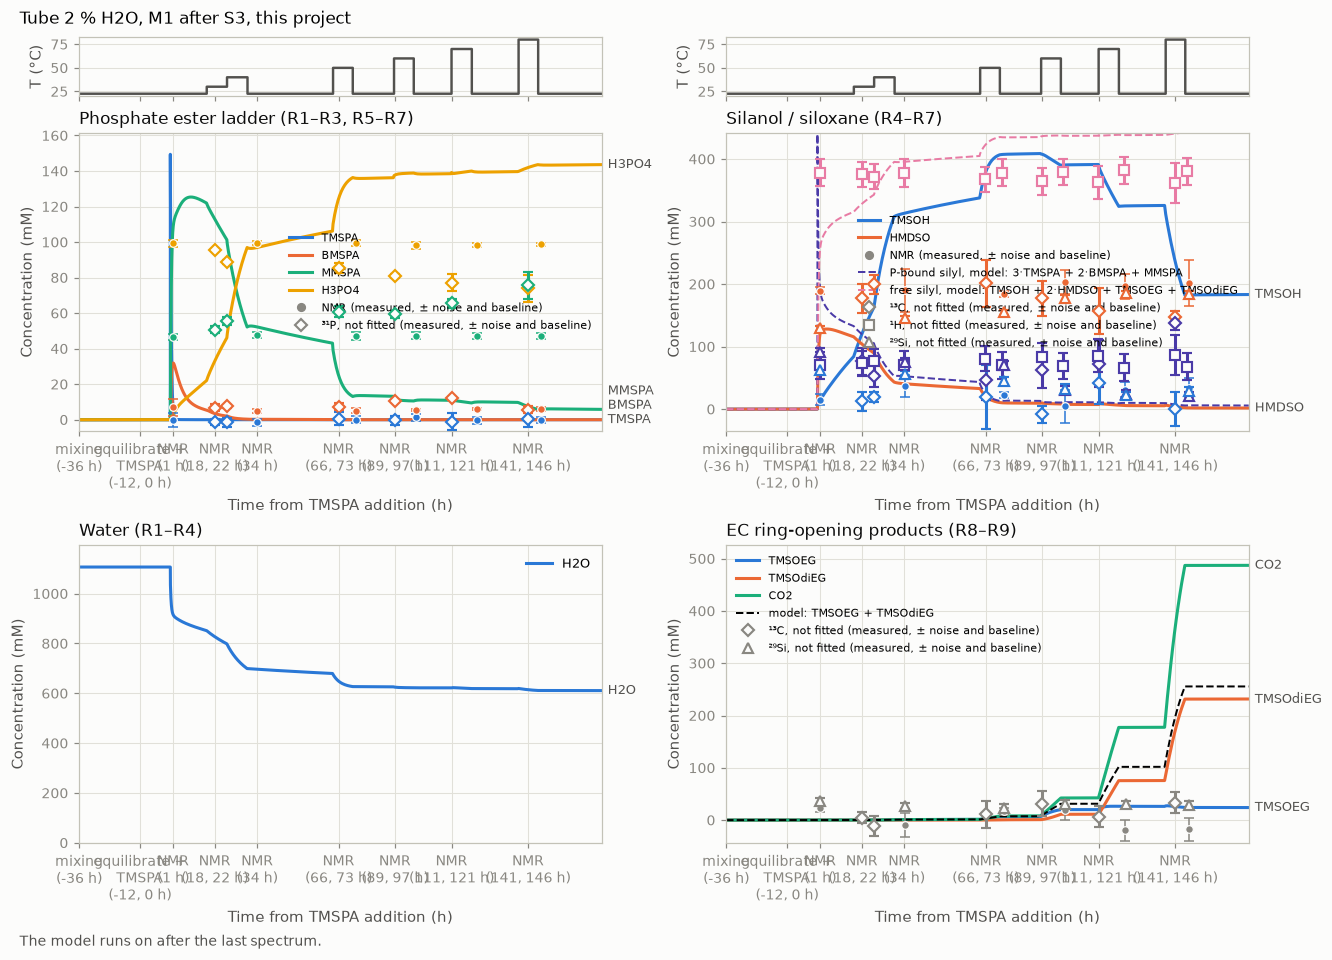

In [3]:
fit = load_fit_result(str(RESULTS / 'steps' / f"{MAIN}__S5__{SHOWN.replace(' ', '_')}.json"))
tube = '2 % H2O'
files = sort_tube_files(tube, observables)
shares, extra, trajectories = tabulate_tube_spectra(evaluate_all_roles(fit), tube, observables, files)
fig = draw_tube(tube, f'{MAIN} after S3, this project', shares, trajectories, reading=SHOWN)
display(fig)
plt.close(fig)

---
## 3. Computed reaction energies

- $\Delta G_{gas,i}$: gas-phase part (ωB97M-V, RRHO);
- $\Delta E_{solv,i}$: solvation part (MD; an energy, not a free energy);
- $\Delta σ_{solv,i}$: its standard error (MD sampling only: no DFT or solvent-model error);

In [4]:
network = get_active_network()
thermo = calculate_network_thermo(298.15, network=network)
table = pd.DataFrame({'reaction': thermo['equation'].str.replace('H2O', 'H₂O').str.replace('H3PO4', 'H₃PO₄').str.replace('CO2', 'CO₂'),
                      'family': thermo['class'].str.replace('_', ' '),
                      'ΔG_gas (eV)': thermo['dG_gas_eV'], 'ΔΔE_solv (eV)': thermo['ddE_solv_eV'], 'σ_solv (eV)': thermo['sigma_solv_eV'],
                      'ΔG_rxn (eV)': thermo['dG_rxn_eV'], 'ΔG_rxn (kcal/mol)': thermo['dG_rxn_eV'] / KCAL_EV, 'K': thermo['K_eq']})
display(table.style.format({'ΔG_gas (eV)': '{:+.3f}', 'ΔΔE_solv (eV)': '{:+.3f}', 'σ_solv (eV)': '{:.3f}', 'ΔG_rxn (eV)': '{:+.3f}',
                            'ΔG_rxn (kcal/mol)': '{:+.2f}', 'K': '{:.3g}'})
        .set_caption(f"Computed reaction energies at 298.15 K, {CONFIG['medium'].label()}"))

,reaction,family,ΔG_gas (eV),ΔΔE_solv (eV),σ_solv (eV),ΔG_rxn (eV),ΔG_rxn (kcal/mol),K
R1,TMSPA + H₂O ⇌ BMSPA + TMSOH,hydrolysis,+0.139,-0.392,0.104,-0.253,-5.83,1.86e+04
R2,BMSPA + H₂O ⇌ MMSPA + TMSOH,hydrolysis,+0.149,-0.331,0.094,-0.182,-4.20,1.2e+03
R3,MMSPA + H₂O ⇌ H₃PO₄ + TMSOH,hydrolysis,+0.192,-0.252,0.081,-0.061,-1.41,10.7
R4,2 TMSOH ⇌ HMDSO + H₂O,condensation,-0.132,+0.229,0.120,+0.097,+2.25,0.0226
R5,TMSPA + TMSOH ⇌ BMSPA + HMDSO,transfer,+0.008,-0.163,0.111,-0.155,-3.58,421
R6,BMSPA + TMSOH ⇌ MMSPA + HMDSO,transfer,+0.017,-0.102,0.102,-0.085,-1.95,27.1
R7,MMSPA + TMSOH ⇌ H₃PO₄ + HMDSO,transfer,+0.060,-0.023,0.090,+0.036,+0.84,0.242
R8,EC + TMSOH ⇌ TMSOEG + CO₂,solvent attack,-0.323,+0.436,0.103,+0.113,+2.60,0.0125
R9,EC + TMSOEG ⇌ TMSOdiEG + CO₂,solvent attack,-0.331,+0.316,0.106,-0.016,-0.37,1.85
N10,2 BMSPA ⇌ MMSPA + TMSPA,exchange,+0.010,+0.061,0.138,+0.070,+1.63,0.0644


---
## 4. Solvation correction effect

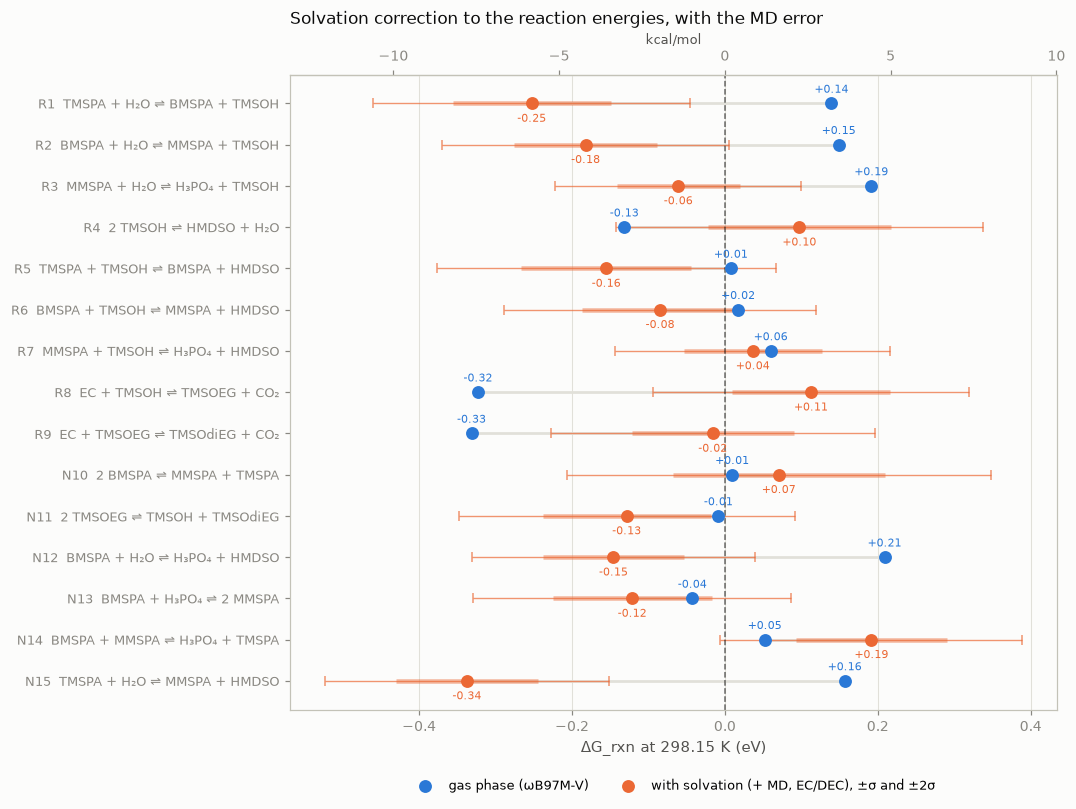

In [5]:
rows = table.iloc[::-1]                                   # R1 at the top
y = np.arange(len(rows))
COLOR_GAS, COLOR_SOLV = style.SERIES[0], style.SERIES[1]
fig, ax = plt.subplots(figsize=(9, 0.42 * len(rows) + 1.2))
for yi, (_, row) in zip(y, rows.iterrows()):
    ax.plot([row['ΔG_gas (eV)'], row['ΔG_rxn (eV)']], [yi, yi], color=fit_plots.GRID, lw=1.8, zorder=1)
ax.errorbar(rows['ΔG_rxn (eV)'], y, xerr=2 * rows['σ_solv (eV)'], fmt='none', ecolor=COLOR_SOLV, elinewidth=0.9, capsize=3, alpha=0.7, zorder=2)
ax.errorbar(rows['ΔG_rxn (eV)'], y, xerr=rows['σ_solv (eV)'], fmt='none', ecolor=COLOR_SOLV, elinewidth=3.0, capsize=0, alpha=0.45, zorder=2)
ax.scatter(rows['ΔG_gas (eV)'], y, color=COLOR_GAS, s=55, zorder=3, label='gas phase (ωB97M-V)')
ax.scatter(rows['ΔG_rxn (eV)'], y, color=COLOR_SOLV, s=55, zorder=3, label='with solvation (+ MD, EC/DEC), ±σ and ±2σ')
for yi, (_, row) in zip(y, rows.iterrows()):
    ax.annotate(f"{row['ΔG_gas (eV)']:+.2f}", (row['ΔG_gas (eV)'], yi), xytext=(0, 7), textcoords='offset points', ha='center', fontsize=7.5, color=COLOR_GAS)
    ax.annotate(f"{row['ΔG_rxn (eV)']:+.2f}", (row['ΔG_rxn (eV)'], yi), xytext=(0, -12), textcoords='offset points', ha='center', fontsize=7.5, color=COLOR_SOLV)
ax.axvline(0, color=fit_plots.INK, lw=1, ls='--', alpha=0.6)
ax.set_yticks(y, [f"{rxn}  {eq}" for rxn, eq in zip(rows.index, rows['reaction'])], fontsize=8.5)
ax.set_xlabel('ΔG_rxn at 298.15 K (eV)')
ax.set_title('Solvation correction to the reaction energies, with the MD error', loc='left')
ax.grid(axis='y', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=2, fontsize=8.5, frameon=False)
top = ax.secondary_xaxis('top', functions=(lambda e: e / KCAL_EV, lambda k: k * KCAL_EV))
top.set_xlabel('kcal/mol', fontsize=8.5)
plt.show()

---
## 5. Fitting

- 1. Variables

$E_{solv,i}, \quad i \in \{TMSPA,\ BMSPA,\ MMSPA,\ H_3PO_4,\ H_2O,\ TMSOH,\ HMDSO\}$

- 2. Parameters

$G_{gas,i}, \quad SD_i, \quad \nu_{i,j}, \quad T, \quad c_0$

- 3. Boundaries

$E_{solv,i} \in [\Delta E_i \pm \xi \cdot SD_i]$

- 4. Objective function

$Ob.F. = \min \chi^2 = \min \sum_k \left( \frac{s_k^{model} - s_k^{NMR}}{\sigma_k} \right)^2$

In [6]:
# Variables
FREE = ['TMSPA', 'BMSPA', 'MMSPA', 'H3PO4', 'H2O', 'TMSOH', 'HMDSO']
species_db = resolve_species_database(None)
sigma = calculate_solvation_sigma_components()
display(pd.DataFrame({'ΔE_solv (eV)': [species_db[sp]['dE_solv_eV'] for sp in FREE],
                      'SD (eV)': [sigma[sp][0] for sp in FREE]}, index=pd.Index(FREE, name='species')).round(3))

# Parameters
T_K = 298.15
REACTIONS = ['R1', 'R2', 'R3', 'R4']
TUBES = ['2 % H2O', 'TMSPa + TMSOH (A)']

# Boundary
XI = 1.0      # ξ: a new sigma, E_solv,i within ±ξ·SD_i; ξ = 2 doubles the interval

# Objective function
# fit = fit_thermo(FREE, xi=XI, reactions=REACTIONS, tubes=TUBES, T_K=T_K)

,ΔE_solv (eV),SD (eV)
species,,
TMSPA,-0.923,0.058
BMSPA,-1.302,0.060
MMSPA,-1.619,0.039
H3PO4,-1.858,0.036
H2O,-0.864,0.033
TMSOH,-0.877,0.052
HMDSO,-0.662,0.051
